<a href="https://colab.research.google.com/github/EvanFarrell7Stu/machinelearning_project_colab/blob/main/CampusProj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Campus Data


## Data Preparation

In [7]:
import pandas as pd

In [8]:
df= pd.read_csv('/content/drive/MyDrive/Colab Notebooks/CampusWalkDataset_TemplateIDs_0610.csv', skiprows=4)

# Keep only the first 22 columns of the DataFrame
df = df.iloc[:, :22]

In [9]:
# Select a specific column using bracket notation (recommended)
location_column = df['location']
display(location_column.head(10))

# Or select a column using dot notation
# weather_column = df.weather

,location
0,L01 MainEntrance
1,L02 LibraryGreen
2,L06 HedgingBehindSportsCentre
3,L08 AccessRoadNearSportsCentre
4,L06 HedgingBehindSportsCentre
5,L01 MainEntrance
6,L04 PathFrontiHub
7,L05 GreenFrontSportsCentre
8,L06 HedgingBehindSportsCentre
9,L07 CarParkNearSportsCentre


In [10]:


print('Column names')
print(df.dtypes)
display(df.head(134))

Column names
recorder_id                               object
date                                      object
location                                  object
weather                                   object
temperature_c                             object
sound level                               object
foot_traffic                              object
primary_sound_type_urban                  object
other_sound_type_urban                    object
primary_sound_type_nature                 object
other_sound_type_nature                   object
insects_count                            float64
birds_count                              float64
trees_presence                            object
native_or_wild_plant_presence             object
ornnamental_or_planted_plant_presence     object
moss_or_lichen_presence                   object
wellbeing_rating                          object
ease_rating                               object
stress_rating                             object
nature_

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,...,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element
0,R26_001,22/09/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,...,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees
1,R26_001,22/09/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,...,2.0,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass
2,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,...,20.0,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet
3,R26_001,22/09/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,...,2.0,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind
4,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,...,0.0,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129,R26_027,23/09/2026,L01 MainEntrance,Partly cloudy,17C,Moderate,High,Traffic,Human voices,Trees,...,3.0,Many,Some,NaN,Many,Positive wellbeing,Neutral,Mostly calm,A little more connected,Grass
130,R26_027,23/09/2026,L07 CarParkNearSportsCentre,Sunny,19C,Moderate,Moderate,Traffic,Human voices,Trees,...,3.0,One or two,Many,NaN,NaN,Neutral,Easy,Mostly calm,No change,Plants
131,R26_027,23/09/2026,L06 HedgingBehindSportsCentre,Sunny,18C,Moderate,Moderate,Human voices,Traffic,Wind,...,2.0,One or two,Some,NaN,NaN,Positive wellbeing,Easy,Mostly calm,A little more connected,Grass
132,R26_027,23/09/2026,L05 GreenFrontSportsCentre,Windy,16C,Quiet,Low,Traffic,Human voices,Other birds,...,0.0,Many,Some,Some,Some,Low wellbeing,Slighly uneasy,Neutral,Less connected,Trees


In [11]:
# Select a specific column using bracket notation (recommended)
location_column = df['location']
foot_traffic_column = df['foot_traffic']
display(location_column.head(134), foot_traffic_column.head(134))




,location
0,L01 MainEntrance
1,L02 LibraryGreen
2,L06 HedgingBehindSportsCentre
3,L08 AccessRoadNearSportsCentre
4,L06 HedgingBehindSportsCentre
...,...
129,L01 MainEntrance
130,L07 CarParkNearSportsCentre
131,L06 HedgingBehindSportsCentre
132,L05 GreenFrontSportsCentre


,foot_traffic
0,Low
1,Low
2,Low
3,Low
4,Low
...,...
129,High
130,Moderate
131,Moderate
132,Low


In [12]:
# Drop NaN values specifically from 'foot_traffic' column
df = df.dropna(subset=['foot_traffic'])
df = df.dropna(subset=['location'])


# Use .unique() with parentheses to get the unique elements in the series
unique_ft =foot_traffic_column.unique()
display(unique_ft)


#get unique values for all locations
unique_locations = location_column.unique()
display(unique_locations)

array(['Low', 'Moderate', 'High', nan, 'low'], dtype=object)

array(['L01 MainEntrance', 'L02 LibraryGreen',
       'L06 HedgingBehindSportsCentre', 'L08 AccessRoadNearSportsCentre',
       'L04 PathFrontiHub', 'L05 GreenFrontSportsCentre',
       'L07 CarParkNearSportsCentre', 'L03 LowerSidePathiHub', nan],
      dtype=object)

In [25]:
# 1. Drop NaN values specifically from 'foot_traffic' and 'location' columns in-place on df
df = df.dropna(subset=['foot_traffic', 'location'])

#foot traffic dictionary
ft_dict = {
    'Low': 1,
    'Moderate': 2,
    'High': 3,
    'low': 1
}

#location dictionary
location_dict = {
    'L01 MainEntrance': 1,
    'L02 LibraryGreen': 2,
    'L03 LowerSidePathiHub': 3,
    'L04 PathFrontiHub': 4,
    'L05 GreenFrontSportsCentre': 5,
    'L06 HedgingBehindSportsCentre': 6,
    'L07 CarParkNearSportsCentre': 7,
    'L08 AccessRoadNearSportsCentre': 8
}

# Show unique values after conversion
print("Unique foot_traffic_encoded values after mapping:", df['location_dict'].unique())
print("Unique location_encoded values after mapping:", df['location_encoded'].unique())

KeyError: 'location_dict'

In [17]:
import matplotlib.pyplot as plt
import numpy as np

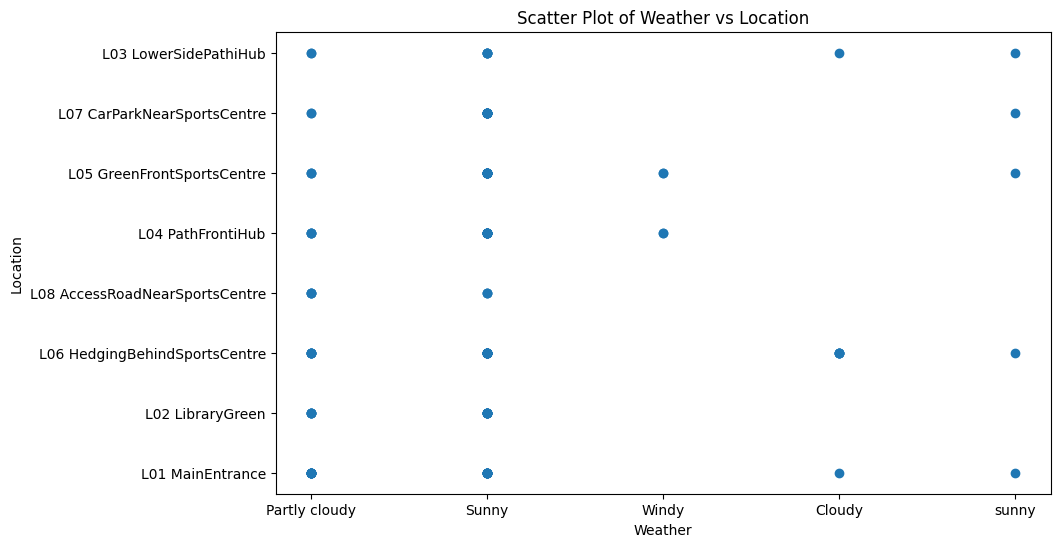

In [18]:
# Drop rows where weather or location is missing to avoid categorical plotting errors with float NaNs
plot_data = df[['weather', 'location']].dropna()

plt.figure(figsize=(10, 6))
plt.scatter(
  plot_data['weather'],
  plot_data['location']
)
plt.xlabel('Weather')
plt.ylabel('Location')
plt.title('Scatter Plot of Weather vs Location')
plt.show()

### Strip Plot of Foot Traffic by Location (Using Masked Values)

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Filter out missing values using your newly encoded columns
plot_df = df[['foot_traffic_encoded', 'location_encoded']].dropna()

# Define original labels for clear axes readability
location_labels = {
    1: 'L01 MainEntrance',
    2: 'L02 LibraryGreen',
    3: 'L03 LowerSidePathiHub',
    4: 'L04 PathFrontiHub',
    5: 'L05 GreenFrontSportsCentre',
    6: 'L06 HedgingBehindSportsCentre',
    7: 'L07 CarParkNearSportsCentre',
    8: 'L08 AccessRoadNearSportsCentre'
}
ft_labels = {1: 'Low (1)', 2: 'Moderate (2)', 3: 'High (3)'}

# Convert mapped columns to numeric for plotting and numeric jittering
x_coords = pd.to_numeric(plot_df['foot_traffic_encoded']).values
y_coords = pd.to_numeric(plot_df['location_encoded']).values

# Generate horizontal jitter using numpy
np.random.seed(42)
jitter = np.random.uniform(-0.15, 0.15, size=len(x_coords))
x_jittered = x_coords + jitter

# Create the plot
plt.figure(figsize=(10, 8))
plt.scatter(x_jittered, y_coords, alpha=0.6, edgecolors='black', linewidths=0.5, s=70, color='teal')

# Set limits, ticks, and labels
plt.xlim(0.5, 3.5)
plt.ylim(0.5, 8.5)
plt.xticks(ticks=[1, 2, 3], labels=[ft_labels[1], ft_labels[2], ft_labels[3]])
plt.yticks(ticks=list(location_labels.keys()), labels=list(location_labels.values()))

plt.xlabel('Foot Traffic Level (Mapped)')
plt.ylabel('Location (Mapped)')
plt.title('Strip Plot: Foot Traffic by Location')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

ValueError: Unable to parse string "Low" at position 0

In [21]:

display(stress_rating_column.unique())




NameError: name 'stress_rating_column' is not defined

In [ ]:
#Python dictionary used here
stress_label={
    'Very stressful': 5,
    'Stressful': 4,
    'Neutral': 3,
    'Mostly calm': 2,
    'Very calm': 1

}




### Encoding Stress Rating

To map text values like `'Stressful'` or `'Neutral'` to numeric values, the dictionary keys must be the strings. We can dynamically reverse your `stress_label` dictionary to create an encoder map, and then use `.map()` to create a new encoded column.

In [ ]:
# Map the text column directly using your corrected stress_label dictionary
df['stress_rating_encoded'] = df['stress_rating'].map(stress_label)

# Verify the encoding
display(df[['stress_rating', 'stress_rating_encoded']].head(10))

In [ ]:
from sklearn.preprocessing import StandardScaler

# Convert both encoded columns to numeric type
df['stress_rating_encoded'] = pd.to_numeric(df['stress_rating_encoded'])
df['foot_traffic_encoded'] = pd.to_numeric(df['foot_traffic_encoded'])

#Scaling data
scaler= StandardScaler()
scaled_data = scaler.fit_transform(df[['stress_rating_encoded', 'foot_traffic_encoded']])
df[['stress_rating_encoded', 'foot_traffic_encoded']] = scaled_data

# Calculate correlation
correlation = df['stress_rating_encoded'].corr(df['foot_traffic_encoded'])
print(f"Correlation between Stress Rating (Encoded) and Foot Traffic (Encoded): {correlation:.4f}")

In [ ]:
plt.scatter(df['stress_rating_encoded'], df['foot_traffic_encoded'])
plt.xlabel('Stress Rating (Encoded)')
plt.ylabel('Foot Traffic (Encoded)')
plt.title('Scatter Plot of Encoded Stress Rating vs Encoded Foot Traffic')
plt.show()